# Fullpage v3: eksperimen identity dan fakta

Notebook ini merangkum artefak yang sudah dibuat. Sel-selnya membaca manifest train, profil GPU, log training, dan evaluasi development. Notebook tidak menjalankan ulang training, tidak membuka baris data final, dan tidak mengubah validator.

Semua data curriculum pada eksperimen ini sintetis dan belum ditinjau manusia.

## Alur eksperimen

1. Menambah contoh nama usaha sintetis hanya pada keluarga train.
2. Menjaga manifest validation dan test tetap sama dengan v2.
3. Mengukur batch GPU lalu membekukan konfigurasi training.
4. Melatih TRAIN-020 sampai update 1.800, lalu resume persis sebagai TRAIN-021 sampai update 3.600.
5. Mengevaluasi kedua snapshot pada 80 permintaan development dengan validator yang sama.

In [1]:
import json
from pathlib import Path
from collections import Counter
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd()
def read_json(path):
    return json.loads(Path(path).read_text(encoding='utf-8'))
print('Project root:', ROOT)
print('Final benchmark opened: no')

Project root: F:\Generative_AI\Vibe_Coding_Proyek_1
Final benchmark opened: no


## Dataset v3 dan partisi yang dipertahankan

In [2]:
v2_manifest = read_json(ROOT / 'data/processed/fullpage/v2/manifest.json')
v3_manifest = read_json(ROOT / 'data/processed/fullpage/v3/manifest.json')
augmentation = v3_manifest['augmentation']
heldout_names = ('validation.jsonl', 'validation.requests.jsonl', 'test.jsonl', 'test.requests.jsonl')
heldout_unchanged = {name: v3_manifest['files'][name]['sha256'] == v2_manifest['files'][name]['sha256'] for name in heldout_names}
assert all(heldout_unchanged.values())
pd.DataFrame([
    {'item': 'versi', 'nilai': v3_manifest['version']},
    {'item': 'train families', 'nilai': augmentation['train_families']},
    {'item': 'halaman sintetis baru', 'nilai': augmentation['train_pages_added']},
    {'item': 'alias nama train', 'nilai': augmentation['new_name_aliases']},
    {'item': 'task page_plan baru', 'nilai': augmentation['added_tasks']['page_plan']},
    {'item': 'task section_content baru', 'nilai': augmentation['added_tasks']['section_content']},
    {'item': 'jumlah task train', 'nilai': v3_manifest['task_counts']['train']},
    {'item': 'panjang konteks maksimum', 'nilai': v3_manifest['max_total_tokens']},
    {'item': 'data ditinjau manusia', 'nilai': augmentation['human_reviewed']},
    {'item': 'file heldout sama dengan v2', 'nilai': all(heldout_unchanged.values())},
])

,item,nilai
0,versi,fullpage-v3
1,train families,240
2,halaman sintetis baru,960
3,alias nama train,480
4,task page_plan baru,960
5,task section_content baru,4800
6,jumlah task train,23040
7,panjang konteks maksimum,1932
8,data ditinjau manusia,False
9,file heldout sama dengan v2,True


Perbandingan heldout di atas memakai checksum yang tercatat pada manifest. Notebook tidak membaca isi file test maupun benchmark final.

## Eksposur role section pada train

,v2,v3
hero,4320,5280
footer,2400,3360
about,2400,2400
navigation,480,1440
services,480,1440
portfolio,240,720
faq,240,720
process,480,480
benefits,480,480
contact,480,480


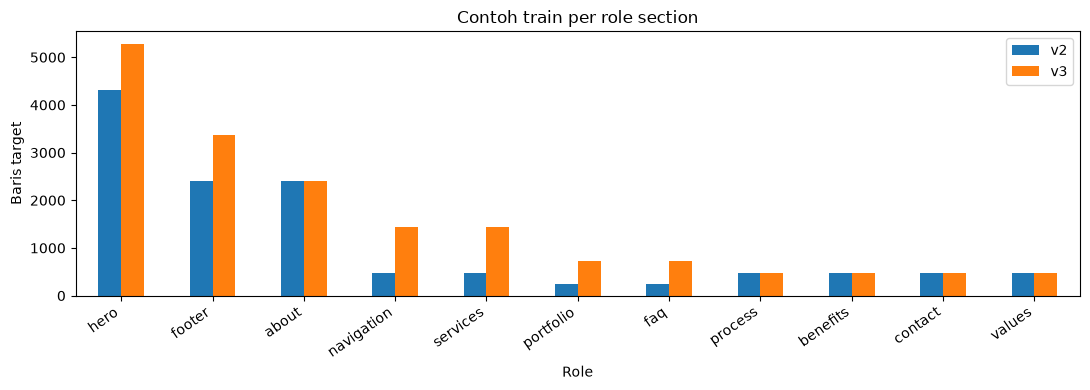

In [3]:
def section_role_counts(path):
    roles = Counter()
    tasks = Counter()
    with Path(path).open(encoding='utf-8') as handle:
        for line in handle:
            row = json.loads(line)
            tasks[row['task']] += 1
            if row['task'] == 'section_content':
                roles[json.loads(row['target']).get('role')] += 1
    return tasks, roles

v2_tasks, v2_roles = section_role_counts(ROOT / 'data/processed/fullpage/v2/train.jsonl')
v3_tasks, v3_roles = section_role_counts(ROOT / 'data/processed/fullpage/v3/train.jsonl')
role_frame = pd.DataFrame({'v2': v2_roles, 'v3': v3_roles}).fillna(0).astype(int).sort_values('v3', ascending=False)
display(role_frame)
ax = role_frame.plot(kind='bar', figsize=(11, 4), title='Contoh train per role section')
ax.set_ylabel('Baris target')
ax.set_xlabel('Role')
plt.xticks(rotation=35, ha='right')
plt.tight_layout()
plt.show()

Data v3 menambah contoh untuk navigation, hero, services, faq atau portfolio, dan footer. Jumlah contoh process tetap 480, sama seperti v2. Ini selaras dengan error JSON pada role process yang muncul di kedua evaluasi, tetapi korelasi ini sendiri belum membuktikan sebab-akibat.

## Profil GPU dan konfigurasi yang dibekukan

In [4]:
profile = read_json(ROOT / 'reports/training/FULLPAGE-GPU-004.json')
profile_rows = profile['results']
display(pd.DataFrame([{
    'batch': row['batch'], 'akumulasi': row['accumulation'],
    'status': row['status'], 'token/detik': round(row.get('tokens_per_second', 0)),
    'VRAM puncak GiB': round(row.get('peak_reserved_bytes', 0) / 2**30, 2),
} for row in profile_rows]))
config = read_json(ROOT / 'configs/fullpage/training-improvement-v3.json')
pd.DataFrame([{'parameter': key, 'nilai': config[key]} for key in ('batch_size', 'gradient_accumulation', 'max_steps', 'plan_batch_probability', 'warmup_steps', 'validation_interval', 'checkpoint_interval')])

,batch,akumulasi,status,token/detik,VRAM puncak GiB
0,4,12,stable,47917,1.26
1,8,6,stable,53546,2.13
2,12,4,stable,53233,3.00
3,16,3,stable,52462,3.90


,parameter,nilai
0,batch_size,8.0
1,gradient_accumulation,6.0
2,max_steps,3600.0
3,plan_batch_probability,0.7
4,warmup_steps,180.0
5,validation_interval,600.0
6,checkpoint_interval,600.0


Catatan perbandingan rasio: konfigurasi TRAIN-019 yang menjadi baseline juga memakai plan_batch_probability 0.7. Jadi perubahan v3 terhadap baseline ada pada data augmentation dan komposisi role, bukan pada rasio sampler.

## Kurva training dan cross-entropy development

,run_id,step,loss,perplexity,valid_tokens
0,TRAIN-020,0,6.266233,526.490117,238822
601,TRAIN-020,600,0.151869,1.164007,238822
1202,TRAIN-020,1200,0.014740,1.014849,238822
1803,TRAIN-020,1800,0.005813,1.005830,238822
1804,TRAIN-021,1800,0.005813,1.005830,238822
2405,TRAIN-021,2400,0.007057,1.007082,238822
3006,TRAIN-021,3000,0.007339,1.007366,238822
3607,TRAIN-021,3600,0.007596,1.007625,238822


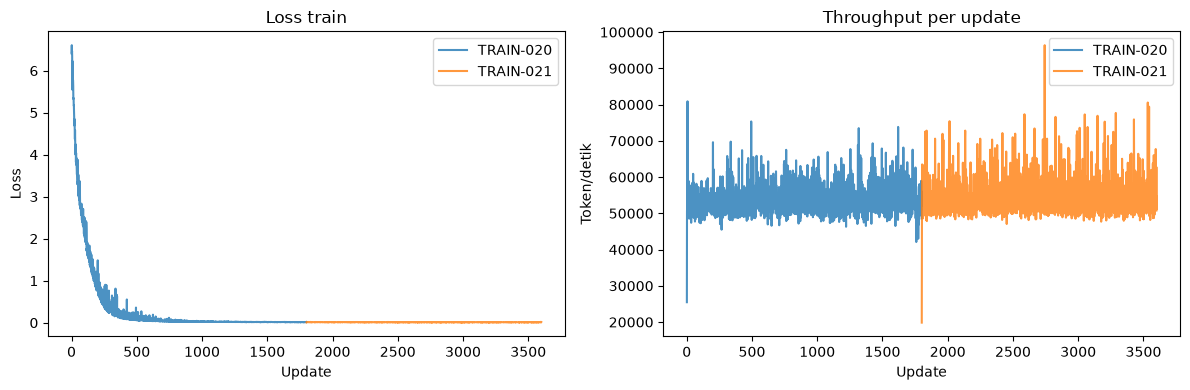

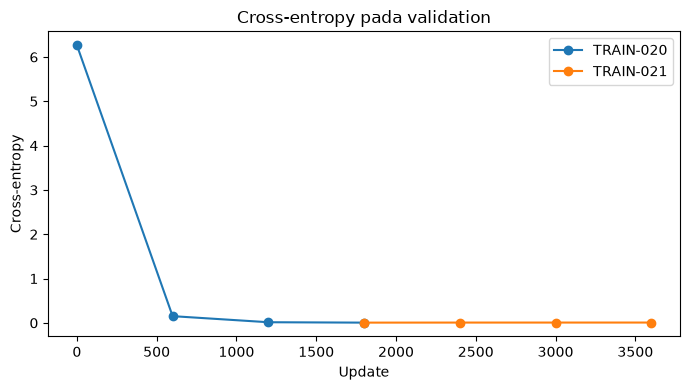

In [5]:
metric_rows = []
for run_id in ('TRAIN-020', 'TRAIN-021'):
    with (ROOT / f'outputs/metrics/{run_id}.jsonl').open(encoding='utf-8') as handle:
        metric_rows.extend({'run_id': run_id, **json.loads(line)} for line in handle if line.strip())
metrics = pd.DataFrame(metric_rows)
train = metrics[metrics['event'] == 'train'].copy()
validation = metrics[metrics['event'] == 'validation'].copy()
display(validation[['run_id', 'step', 'loss', 'perplexity', 'valid_tokens']])
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for run_id, rows in train.groupby('run_id'):
    axes[0].plot(rows['step'], rows['loss'], label=run_id, alpha=.8)
    axes[1].plot(rows['step'], rows['tokens_per_second'], label=run_id, alpha=.8)
axes[0].set_title('Loss train')
axes[0].set_xlabel('Update')
axes[0].set_ylabel('Loss')
axes[1].set_title('Throughput per update')
axes[1].set_xlabel('Update')
axes[1].set_ylabel('Token/detik')
for axis in axes: axis.legend()
plt.tight_layout()
plt.show()
fig, axis = plt.subplots(figsize=(7, 4))
for run_id, rows in validation.groupby('run_id'):
    axis.plot(rows['step'], rows['loss'], marker='o', label=run_id)
axis.set_title('Cross-entropy pada validation')
axis.set_xlabel('Update')
axis.set_ylabel('Cross-entropy')
axis.legend()
plt.tight_layout()
plt.show()

## Hasil evaluasi halaman development

In [6]:
selection = read_json(ROOT / 'reports/training/AI-020_DEVELOPMENT_SELECTION.json')
rows = [{
    'run': selection['baseline']['run_id'], 'update': selection['baseline']['step'],
    'valid': selection['baseline']['development_complete'], 'total': selection['baseline']['development_total'],
    'CE': selection['baseline']['development_ce'], 'gate': 'baseline'
}] + [{
    'run': row['run_id'], 'update': row['step'], 'valid': row['development_complete'],
    'total': row['development_total'], 'CE': row['development_ce'], 'gate': row['model_gate']
} for row in selection['candidates']]
display(pd.DataFrame(rows))
print('Target:', selection['target']['minimum_complete_pages'], 'dari', selection['target']['pages'])
print('Candidate yang lolos gate:', selection['promotable_candidate'])
print('Final dibuka:', selection['final_opened'])

,run,update,valid,total,CE,gate
0,TRAIN-019,3600,70,80,0.007519,baseline
1,TRAIN-020,1800,0,80,0.005813,False
2,TRAIN-021,3600,0,80,0.007596,False


Target: 76 dari 80
Candidate yang lolos gate: None
Final dibuka: False


## Error validator paling sering

In [7]:
error_rows = []
for candidate in selection['candidates']:
    for item in candidate['top_generation_errors']:
        error_rows.append({'run': candidate['run_id'], 'role': item['stage'], 'error': item['error'], 'attempts': item['attempts'], 'halaman terdampak': item['affected_pages']})
display(pd.DataFrame(error_rows).sort_values(['run', 'attempts'], ascending=[True, False]).groupby('run').head(6))

,run,role,error,attempts,halaman terdampak
0,TRAIN-020,process,"Invalid JSON/contract: Expecting ',' delimiter...",128,64
1,TRAIN-020,plan,Plan request identity/style mismatch,15,8
2,TRAIN-020,plan,"plan:['sections', 8, 2]: 'columns' is not one ...",13,11
3,TRAIN-020,plan,"plan:['sections', 8, 3]: ['name'] is not one o...",13,11
4,TRAIN-020,plan,"plan:['sections', 8]: ['footer', 'footer', 'co...",13,11
5,TRAIN-020,about,Required fact text mismatch: about,4,2
9,TRAIN-021,process,"Invalid JSON/contract: Expecting ',' delimiter...",144,72
10,TRAIN-021,plan,Plan request identity/style mismatch,15,8
11,TRAIN-021,plan,"plan:['sections', 8, 2]: 'columns' is not one ...",6,6
12,TRAIN-021,plan,"plan:['sections', 8, 3]: ['name'] is not one o...",6,6


## Kesimpulan

Baseline TRAIN-019 menghasilkan 70/80 halaman development yang lengkap. Pada eksperimen v3, baik update 1.800 maupun 3.600 menghasilkan 0/80. Target 95 persen membutuhkan sedikitnya 76/80. Cross-entropy rendah tidak membuat hasil ini lolos karena rancangan atau bagian halaman tetap gagal pada validator.

Kegagalan yang dominan ialah JSON rusak pada bagian process. Ada juga title usaha yang berubah saat dibuat ulang, misalnya huruf atau suku kata hilang/bertambah. Validator tetap ketat. Tidak ada candidate yang dipromosikan. Evaluasi browser, review manusia, dan final benchmark tidak dilakukan.

## Bukti dan batas penggunaan

RUN utama: RUN-295 persiapan data, RUN-297 profil GPU, RUN-300 dan RUN-308 training, RUN-302 dan RUN-310 evaluasi, RUN-320 pemilihan checkpoint. Detail setiap eksekusi ada di logs/LOG_EKSPERIMEN_DAN_INTERAKSI_LLM.md dan logs/RUN-*.txt.

Notebook ini adalah ringkasan hasil lokal. Ia tidak membuktikan kualitas visual browser, generalisasi ke data nyata, atau kelayakan produksi.